<a href="https://colab.research.google.com/github/csanlag861-dev/BigData/blob/main/ejercicio_graficos_cristiansanchez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
df = pd.read_csv("/content/drive/MyDrive/dataset/fc27-players-2026-10-11.csv")

In [67]:
df.head()

,base_id,stats_id,first_name,last_name,nation_name,league_name,club_name,full_name,common_name,position,...,pac,sho,pas,dri,def,phy,skill_moves,weak_foot,foot,accelerate
0,228959,228959,Fernando,Alarcón,Argentina,League,Instituto,"Alarcón, Fernando",NaN,CB,...,55.0,33.0,44.0,36.0,68.0,77.0,2,2,Left,Lengthy
1,236885,236885,Brandon,Vazquez,United States,League,Austin FC,"Vazquez, Brandon",NaN,ST,...,74.0,67.0,52.0,64.0,33.0,68.0,2,3,Right,Lengthy
2,238051,238051,Rasmus,Vinderslev,Denmark,League,Sønderjyske,"Vinderslev, Rasmus",NaN,CDM,...,54.0,45.0,55.0,63.0,66.0,79.0,2,3,Right,Lengthy
3,246914,246914,Robert,Rojas,Paraguay,League,Libertad,"Rojas, Robert",NaN,RB,...,73.0,57.0,63.0,63.0,65.0,74.0,2,3,Right,Controlled
4,265136,265136,Gentiana,Fetaj,Kosovo,League,1. FSV Mainz 05,Gentiana Fetaj,NaN,CM,...,72.0,64.0,67.0,69.0,62.0,58.0,4,3,Right,Controlled


In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10762 entries, 0 to 10761
Data columns (total 71 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   base_id             10762 non-null  int64  
 1   stats_id            10762 non-null  int64  
 2   first_name          10762 non-null  object 
 3   last_name           10739 non-null  object 
 4   nation_name         10762 non-null  object 
 5   league_name         10738 non-null  object 
 6   club_name           10738 non-null  object 
 7   full_name           10762 non-null  object 
 8   common_name         1618 non-null   object 
 9   position            10762 non-null  object 
 10  position_alt        10674 non-null  object 
 11  position_alt_2      7182 non-null   object 
 12  position_alt_3      4060 non-null   object 
 13  rating              10762 non-null  int64  
 14  height              10345 non-null  float64
 15  acceleration        10762 non-null  int64  
 16  aggr

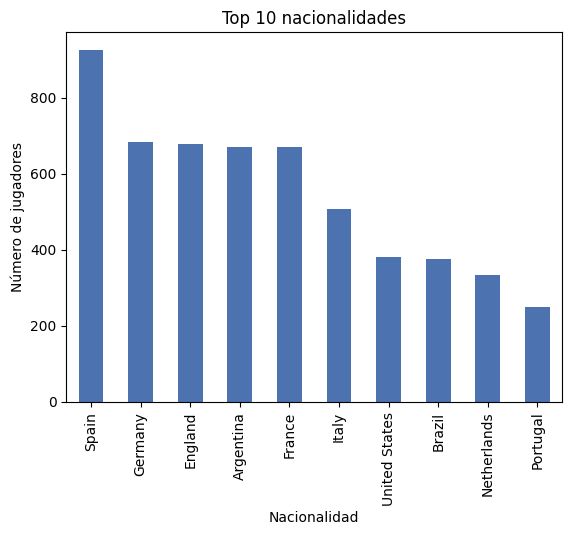

In [69]:
# Gráfico de Barras - Top Nacionalidades (Comparación)

## Matplotlib

top_nacionalidades = df["nation_name"].value_counts().head(10)
top_nacionalidades.plot.bar(title="Top 10 nacionalidades")

plt.ylabel("Número de jugadores")
plt.xlabel("Nacionalidad")
plt.show()



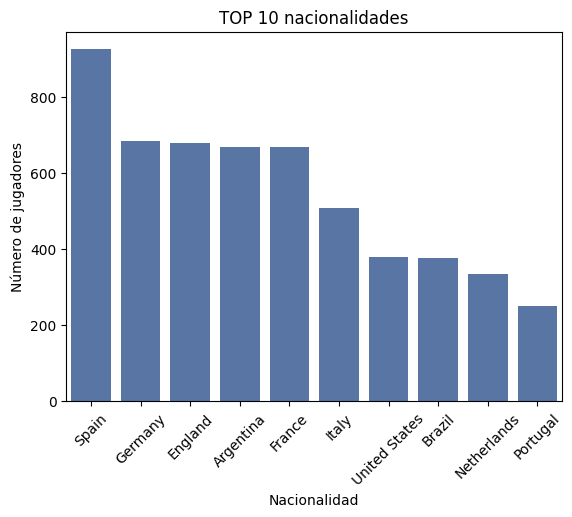

In [70]:
## Seaborn
sns.set_palette("deep")

sns.barplot(x=top_nacionalidades.index, y=top_nacionalidades.values)
plt.title("TOP 10 nacionalidades")
plt.xlabel("Nacionalidad")
plt.ylabel("Número de jugadores")
plt.xticks(rotation=45)
plt.show()

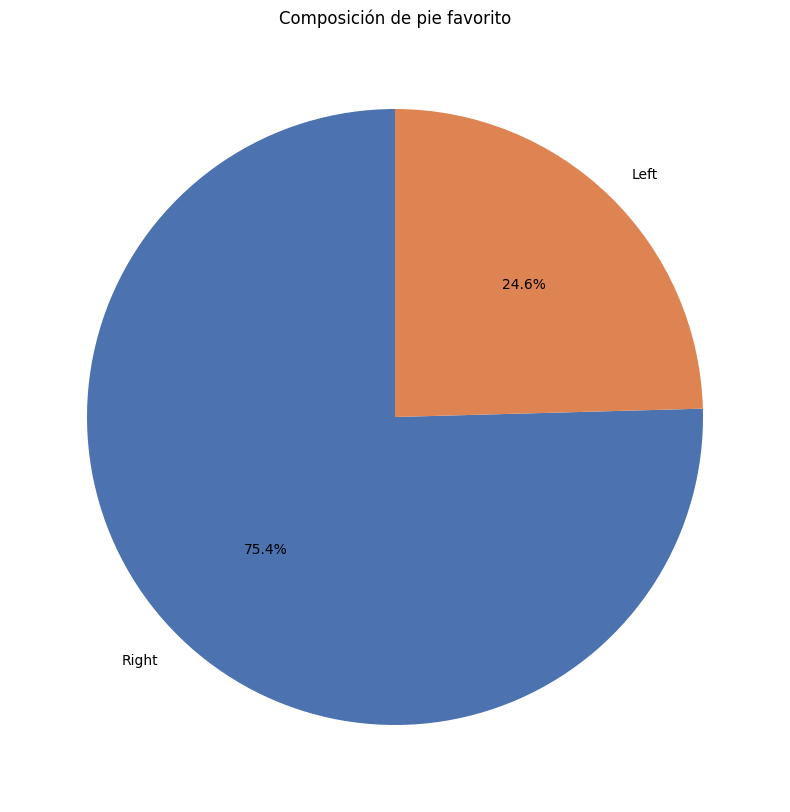

In [71]:
# Gráfico de Tarta - Pie Favorito (Composición)

## Matplotlib & seaborn
pie_favorito = df["foot"]

plt.figure(figsize=(10,10))

plt.pie(pie_favorito.value_counts(), labels=pie_favorito.value_counts().index, autopct="%1.1f%%", startangle=90)
plt.title("Composición de pie favorito")

plt.show()

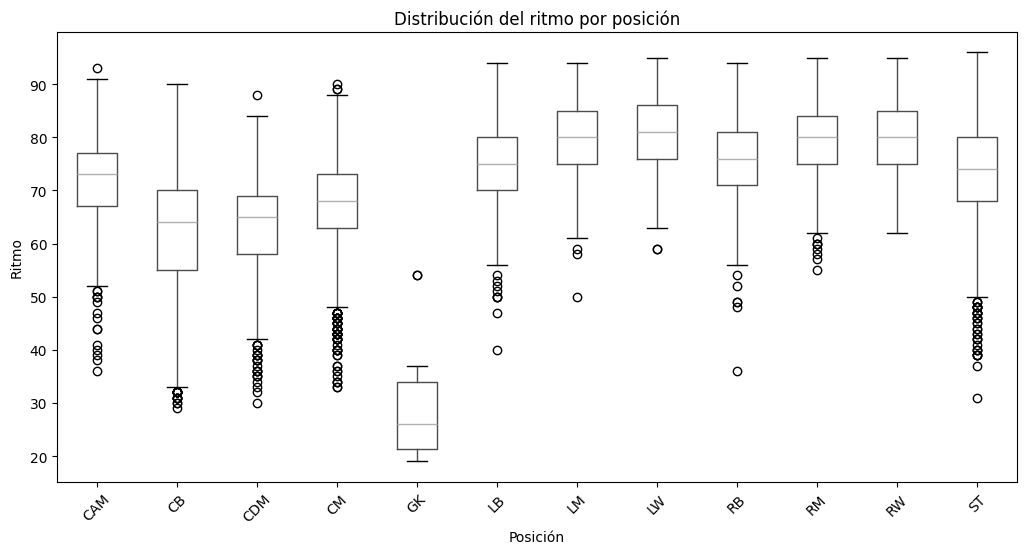

In [72]:
# Gráfico de Diagrama de Caja - Distribución del ritmo por posición (Distribución)

## Matplotlib
df.boxplot(column="pac", by="position", figsize=(12, 6), grid=False)

plt.suptitle("")
plt.title("Distribución del ritmo por posición")
plt.xlabel("Posición")
plt.ylabel("Ritmo")
plt.xticks(rotation=45)
plt.show()

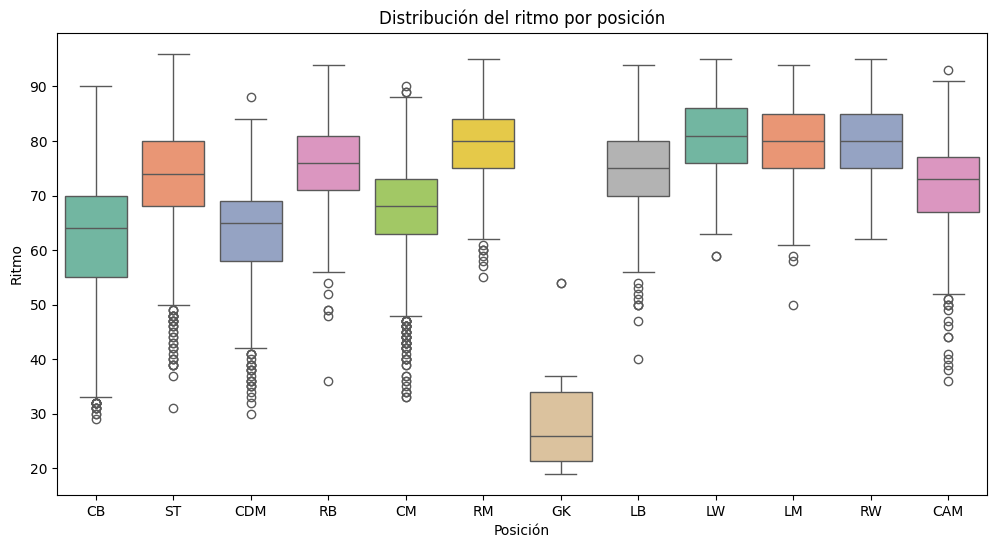

In [73]:
## Seaborn
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="position", y="pac", hue="position", palette="Set2")

plt.title("Distribución del ritmo por posición")
plt.xlabel("Posición")
plt.ylabel("Ritmo")
plt.show()

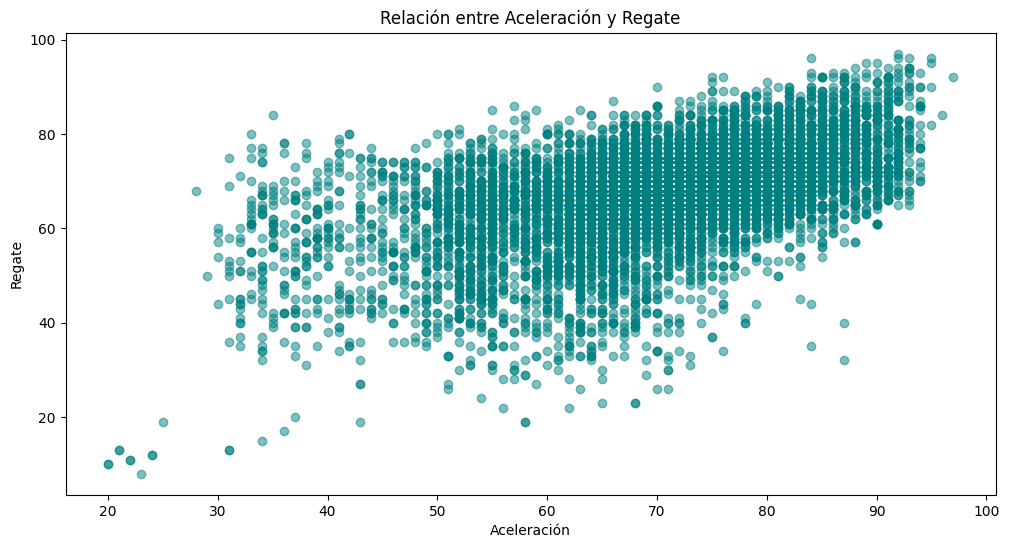

In [74]:
# Gráfico de Dispersión - Relación entre aceleración y tiro (Relación)

## Matplotlib
plt.figure(figsize=(12, 6))

plt.scatter(df["acceleration"], df["dribbling"], alpha=0.5, color="teal")

plt.title("Relación entre Aceleración y Regate")

plt.xlabel("Aceleración")
plt.ylabel("Regate")

plt.show()

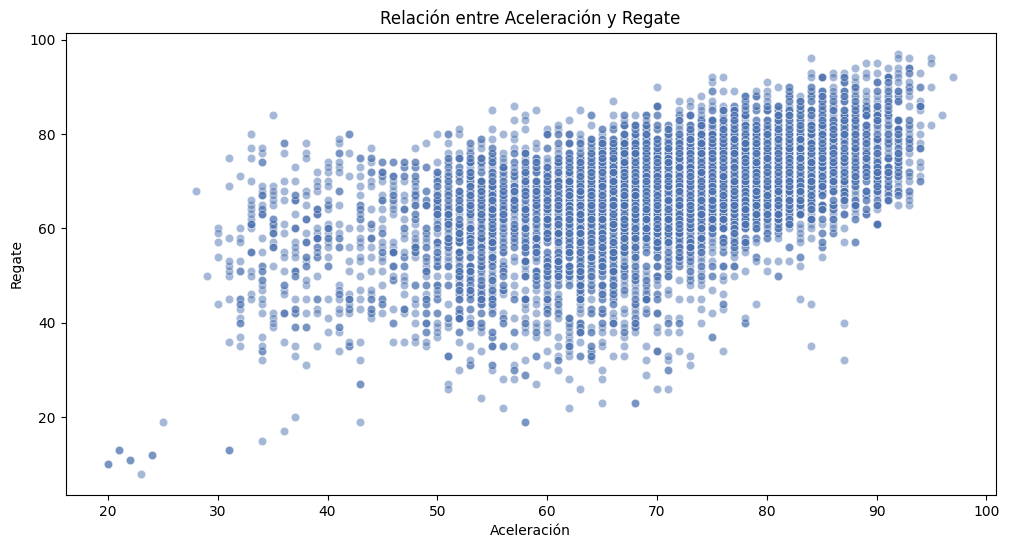

In [75]:
## Seaborn
plt.figure(figsize=(12, 6))

sns.scatterplot(data=df, x="acceleration", y="dribbling", alpha=0.5)

plt.title("Relación entre Aceleración y Regate")
plt.xlabel("Aceleración")
plt.ylabel("Regate")
plt.show()

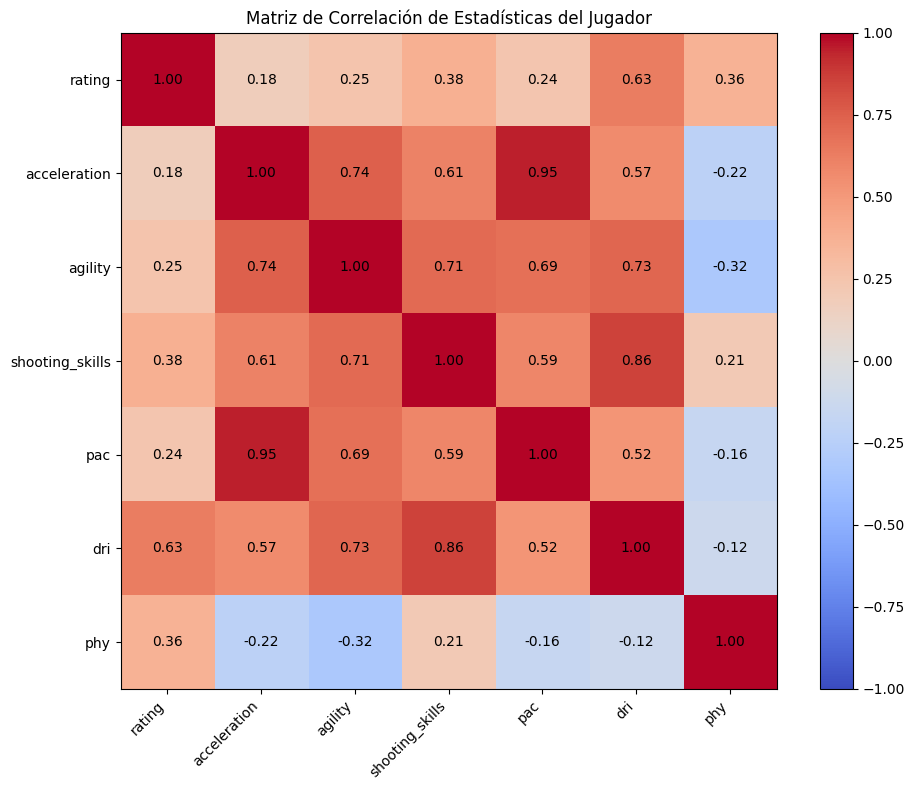

In [76]:
# Gráfico de Mapa de Calor - Correlación entre las stats principales (Relación)

## Matplotlib
columnas = ["rating", "acceleration", "agility", "shooting_skills", "pac", "dri", "phy"]
matriz_corr = df[columnas].corr()


fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(matriz_corr, cmap="coolwarm", vmin=-1, vmax=1)

fig.colorbar(cax)
ax.set_xticks(range(len(columnas)))
ax.set_yticks(range(len(columnas)))
ax.set_xticklabels(columnas, rotation=45, ha="right")
ax.set_yticklabels(columnas)

for i in range(len(columnas)):
    for j in range(len(columnas)):
        valor = matriz_corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", color="black")

ax.set_title("Matriz de Correlación de Estadísticas del Jugador")
plt.tight_layout()
plt.show()

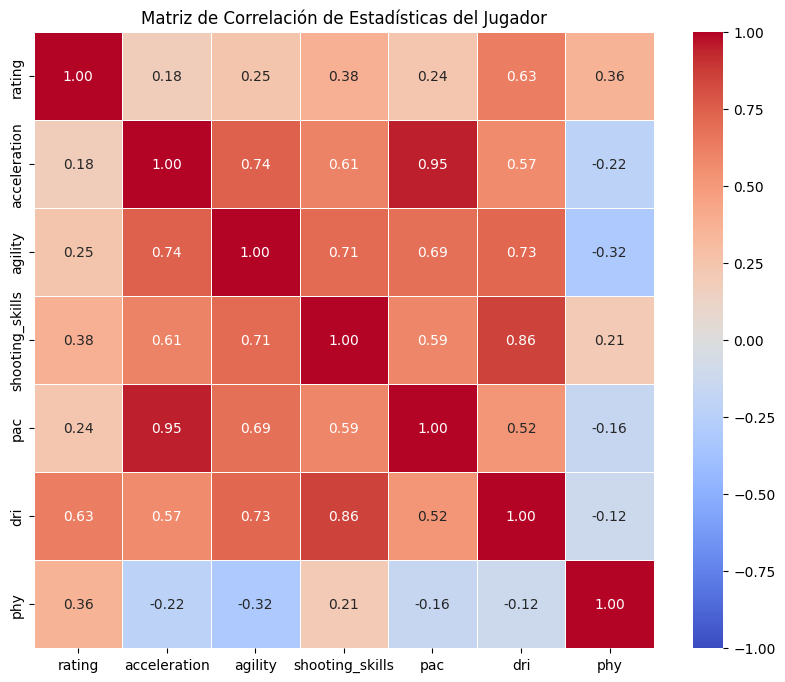

In [77]:
## Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Matriz de Correlación de Estadísticas del Jugador")
plt.show()